# Tema 4, Exercițiul 2
## Putem prezice vremea la o stație fără observații?

O regiune are $n$ stații meteo $S_1, \dots, S_n$, fiecare cu trei stări: Soare, Ploaie, Nori. Stațiile vecine tind să aibă vreme asemănătoare. Modelăm acest lucru cu o rețea Markov (graf neorientat) în care nodurile sunt stațiile, iar muchiile leagă stațiile vecine.

Alegem $n = 5$ și muchiile $S_0{-}S_1,\; S_1{-}S_2,\; S_1{-}S_3,\; S_3{-}S_4$, care formează un arbore.

Distribuția comună este produsul normalizat al tuturor factorilor:

$$P(s_1, \dots, s_n) = \frac{1}{Z} \prod_{i=1}^{n} \phi_i(s_i) \prod_{(i,j) \in E} \phi_{ij}(s_i, s_j), \qquad Z = \sum_{s} \prod_i \phi_i(s_i)\prod_{(i,j)}\phi_{ij}(s_i,s_j).$$

## a) Graful și vecinii

Desenăm graful și verificăm că este un arbore (fără cicluri).

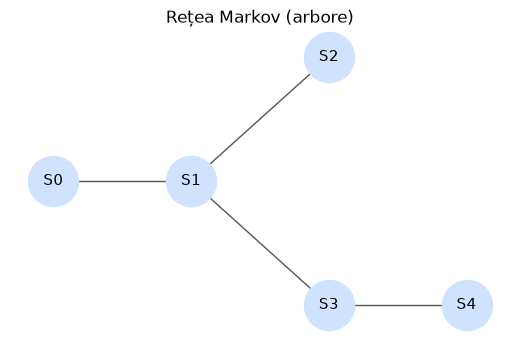

vecinii lui S0: [1]
vecinii lui S1: [0, 2, 3]
vecinii lui S2: [1]
vecinii lui S3: [1, 4]
vecinii lui S4: [3]
este arbore: True


In [1]:
import numpy as np
import itertools
import networkx as nx
import matplotlib.pyplot as plt

numar_statii = 5
# fiecare pereche (i, j) = o muchie intre statiile S_i si S_j
muchii = [(0, 1), (1, 2), (1, 3), (3, 4)]

# construim graful neorientat al retelei
graf = nx.Graph()
graf.add_nodes_from(range(numar_statii))
graf.add_edges_from(muchii)

# pozitii fixe pentru desen (ca sa arate ca un arbore)
pozitii = {0: (0, 1), 1: (1, 1), 2: (2, 1.6), 3: (2, 0.4), 4: (3, 0.4)}
plt.figure(figsize=(5, 3))
nx.draw(graf, pozitii, with_labels=True,
        labels={i: f"S{i}" for i in range(numar_statii)},
        node_color="#cfe3ff", node_size=1300, font_size=11, edge_color="#555")
plt.title("Rețea Markov (arbore)")
plt.axis("off")
plt.show()

# afisam vecinii fiecarei statii
for i in range(numar_statii):
    print(f"vecinii lui S{i}:", sorted(graf.neighbors(i)))
# un graf conex cu n noduri si n-1 muchii este un arbore (fara cicluri)
print("este arbore:", nx.is_tree(graf))

## b) Modelul Markov în pyAgrum

Definim stările, probabilitățile inițiale $p_i(s)$ (aceleași la toate stațiile) și potențialul pereche $\Psi$ (rânduri/coloane în ordinea Soare, Ploaie, Nori).

In [2]:
import pyagrum as gum

STARI = ["Soare", "Ploaie", "Nori"]
prob_initiala = [0.5, 0.3, 0.2]            # p_i(s): preferinta a priori, la fel pentru toate statiile

# potentialul pereche: cat de compatibile sunt doua statii vecine
# rand = starea statiei i, coloana = starea statiei j (ordinea Soare, Ploaie, Nori)
potential_pereche = np.array([[0.7, 0.2, 0.1],
                              [0.2, 0.6, 0.2],
                              [0.1, 0.3, 0.6]])
# NU e o matrice de probabilitati conditionate -> randurile nu trebuie sa dea 1
print("suma pe randuri:", potential_pereche.sum(axis=1))

suma pe randuri: [1. 1. 1.]


Construim un `MarkovRandomField`: adăugăm variabilele, apoi câte un factor unar pentru fiecare stație și un factor pereche pentru fiecare muchie.

Pentru factorul pereche fixăm explicit $\phi_{ij}(s_i, s_j) = \Psi_{s_i, s_j}$.

In [3]:
model = gum.MarkovRandomField("meteo")

# adaugam cate o variabila (nod) pentru fiecare statie, cu cele 3 stari
for i in range(numar_statii):
    model.add(gum.LabelizedVariable(f"S{i}", f"S{i}", STARI))

# factori unari: phi_i(s) = prob_initiala(s)
for i in range(numar_statii):
    model.addFactor({f"S{i}"}).fillWith(prob_initiala)

# factori pereche: phi_ij(s_i, s_j) = potential_pereche[s_i, s_j]
# parcurgem toate combinatiile (s_i, s_j) ca sa fixam explicit ordinea argumentelor
def seteaza_factor_pereche(factor, nume_i, nume_j):
    pozitie = gum.Instantiation(factor)
    pozitie.setFirst()
    while not pozitie.end():
        stare_i = pozitie.val(factor.variable(nume_i))
        stare_j = pozitie.val(factor.variable(nume_j))
        factor.set(pozitie, float(potential_pereche[stare_i, stare_j]))
        pozitie.inc()

for (i, j) in muchii:
    nume_i, nume_j = f"S{i}", f"S{j}"
    seteaza_factor_pereche(model.addFactor([nume_i, nume_j]), nume_i, nume_j)

print("variabile:", model.names())
print("numar factori:", len(model.factors()))   # 5 unari + 4 pereche = 9

variabile: {'S0', 'S4', 'S3', 'S1', 'S2'}
numar factori: 9


## c) Graful modelului și formula distribuției comune

Pentru arborele ales, distribuția comună este:

$$P(s_0, \dots, s_4) = \frac{1}{Z}\Big(\prod_{i=0}^{4}\phi_i(s_i)\Big)\,\phi_{01}(s_0,s_1)\,\phi_{12}(s_1,s_2)\,\phi_{13}(s_1,s_3)\,\phi_{34}(s_3,s_4).$$

Afișăm și graful modelului așa cum îl vede pyAgrum (muchiile dintre variabilele care apar împreună într-un factor).

In [4]:
# vecinii fiecarei statii, asa cum ii vede modelul (din factorii pereche)
for i in range(numar_statii):
    print(f"vecinii lui S{i} in model:", sorted(model.neighbours(f"S{i}")))

vecinii lui S0 in model: [1]
vecinii lui S1 in model: [0, 2, 3]
vecinii lui S2 in model: [1]
vecinii lui S3 in model: [1, 4]
vecinii lui S4 in model: [3]


## d) MAP marginal la o stație neobservată

Observăm $S_0 = $ Soare și $S_4 = $ Ploaie. Vrem distribuția marginală la o stație neobservată ($S_2$) și starea cea mai probabilă acolo.

MAP marginal = starea care maximizează marginala *fiecărei* variabile separat: $\arg\max_{s_i} P(s_i \mid \text{observații})$.

In [5]:
observatii = {"S0": "Soare", "S4": "Ploaie"}

# motorul de inferenta calculeaza marginalele, tinand cont de observatii
inferenta = gum.ShaferShenoyMRFInference(model)
inferenta.setEvidence(observatii)
inferenta.makeInference()

# distributia marginala la S2
marginala_S2 = inferenta.posterior("S2")
print(marginala_S2)
print("MAP marginal la S2:", STARI[int(np.argmax(marginala_S2.toarray()))])

# starea cea mai probabila (MAP marginal) pentru fiecare statie neobservata
statii_neobservate = [i for i in range(numar_statii) if f"S{i}" not in observatii]
map_marginal = {}
for i in statii_neobservate:
    marginala = inferenta.posterior(f"S{i}").toarray()
    map_marginal[i] = STARI[int(np.argmax(marginala))]
print("MAP marginal (toate statiile neobservate):",
      {f"S{i}": map_marginal[i] for i in statii_neobservate})


  S2                         │
Soare    │Ploaie   │Nori     │
─────────│─────────│─────────│
 0.7307  │ 0.2016  │ 0.0678  │

MAP marginal la S2: Soare
MAP marginal (toate statiile neobservate): {'S1': 'Soare', 'S2': 'Soare', 'S3': 'Soare'}


## e) Configurația comună MAP

MAP marginal alege, pentru fiecare stație separat, starea cu marginală maximă. MAP comun (MPE) caută o singură configurație a tuturor stațiilor neobservate care maximizează probabilitatea comună:

$$s^* = \arg\max_{s_{\text{neobs}}} P(s_{\text{neobs}} \mid \text{observații}).$$

Cele două nu coincid întotdeauna: starea cea mai probabilă a unei variabile izolată poate să nu facă parte din cea mai probabilă configurație globală.

Pentru $n = 5$ enumerăm cele $3^n$ configurații (brute-force).

In [6]:
def probabilitate_nenormalizata(configuratie):
    """Produsul tuturor factorilor pentru o configuratie (inainte de impartirea la Z)."""
    valoare = 1.0
    for i in range(numar_statii):                 # factori unari
        valoare *= prob_initiala[configuratie[i]]
    for (i, j) in muchii:                          # factori pereche
        valoare *= potential_pereche[configuratie[i], configuratie[j]]
    return valoare

def enumerare_completa(observatii):
    """Parcurge toate configuratiile; returneaza marginalele si configuratia comuna MAP."""
    # transformam observatiile {"S0": "Soare", ...} in {indice_statie: indice_stare}
    # ex: "S0" -> 0 (scoatem litera S), "Soare" -> 0 (pozitia in STARI)
    statii_observate = {}
    for nume, stare in observatii.items():
        indice_statie = int(nume[1:])
        indice_stare = STARI.index(stare)
        statii_observate[indice_statie] = indice_stare

    neobservate = [i for i in range(numar_statii) if i not in statii_observate]

    # pentru fiecare statie neobservata tinem un vector cu probabilitatea fiecarei stari
    marginale = {}
    for i in neobservate:
        marginale[i] = np.zeros(3)

    cea_mai_buna_config = None
    cea_mai_buna_valoare = -1.0
    suma_totala = 0.0                               # suma_totala = Z (constanta de normalizare)

    # produsul cartezian: toate combinatiile de stari pentru statiile neobservate (3^k)
    for combinatie_stari in itertools.product(range(3), repeat=len(neobservate)):
        # construim o configuratie completa a tuturor statiilor
        configuratie = [0] * numar_statii
        # statiile observate primesc starea lor fixa
        for indice_statie, stare in statii_observate.items():
            configuratie[indice_statie] = stare
        # statiile neobservate primesc starile din combinatia curenta
        for pozitie, indice_statie in enumerate(neobservate):
            configuratie[indice_statie] = combinatie_stari[pozitie]

        valoare = probabilitate_nenormalizata(configuratie)
        suma_totala += valoare

        # adunam valoarea la starea corespunzatoare, pentru fiecare statie neobservata
        for i in neobservate:
            stare_curenta = configuratie[i]
            marginale[i][stare_curenta] += valoare

        # retinem configuratia cu cea mai mare probabilitate (MAP comun)
        if valoare > cea_mai_buna_valoare:
            cea_mai_buna_valoare = valoare
            cea_mai_buna_config = configuratie[:]

    # impartim la Z ca sa obtinem probabilitati (marginalele insumeaza 1)
    for i in neobservate:
        marginale[i] = marginale[i] / suma_totala
    return neobservate, marginale, cea_mai_buna_config

neobservate, marginale, config_map = enumerare_completa(observatii)

# verificam ca marginala la S2 coincide cu cea data de motorul de inferenta
marginala_S2 = {stare: round(float(p), 4) for stare, p in zip(STARI, marginale[2])}
print("verificare marginala S2 (brute-force):", marginala_S2)

# starea cea mai probabila la fiecare statie, dupa cele doua criterii
map_marginal = {}
map_comun = {}
for i in neobservate:
    map_marginal[f"S{i}"] = STARI[int(np.argmax(marginale[i]))]
    map_comun[f"S{i}"] = STARI[config_map[i]]
print("MAP marginal :", map_marginal)
print("MAP comun    :", map_comun)

verificare marginala S2 (brute-force): {'Soare': 0.7307, 'Ploaie': 0.2016, 'Nori': 0.0678}
MAP marginal : {'S1': 'Soare', 'S2': 'Soare', 'S3': 'Soare'}
MAP comun    : {'S1': 'Soare', 'S2': 'Soare', 'S3': 'Soare'}


Marginala obținută prin enumerare coincide cu cea dată de `ShaferShenoyMRFInference` (0.7307 / 0.2016 / 0.0678), deci modelul este construit corect.

Pentru această observație ($S_0{=}$ Soare, $S_4{=}$ Ploaie), MAP marginal și MAP comun coincid.

### Contraexemplu: MAP marginal $\neq$ MAP comun

Schimbăm observațiile în $S_0 = $ Ploaie, $S_4 = $ Nori.

In [7]:
observatii_2 = {"S0": "Ploaie", "S4": "Nori"}
neobservate_2, marginale_2, config_map_2 = enumerare_completa(observatii_2)

map_marginal_2 = {}
map_comun_2 = {}
for i in neobservate_2:
    map_marginal_2[f"S{i}"] = STARI[int(np.argmax(marginale_2[i]))]
    map_comun_2[f"S{i}"] = STARI[config_map_2[i]]

print("observatii:", observatii_2)
print("MAP marginal :", map_marginal_2)
print("MAP comun    :", map_comun_2)
for i in neobservate_2:
    distributie = {stare: round(float(p), 4) for stare, p in zip(STARI, marginale_2[i])}
    print(f"  marginala S{i}:", distributie)

observatii: {'S0': 'Ploaie', 'S4': 'Nori'}
MAP marginal : {'S1': 'Ploaie', 'S2': 'Soare', 'S3': 'Ploaie'}
MAP comun    : {'S1': 'Soare', 'S2': 'Soare', 'S3': 'Soare'}
  marginala S1: {'Soare': 0.3357, 'Ploaie': 0.5335, 'Nori': 0.1307}
  marginala S2: {'Soare': 0.4651, 'Ploaie': 0.3922, 'Nori': 0.1426}
  marginala S3: {'Soare': 0.2823, 'Ploaie': 0.3674, 'Nori': 0.3503}


## Interpretare

- **d)** Cu $S_0{=}$ Soare și $S_4{=}$ Ploaie, $S_2$ are cel mai probabil **Soare** ($\approx 0.73$): efectul „vecini asemănători” propagă informația de la stația observată prin arbore.

- **e)** Cu $S_0{=}$ Ploaie, $S_4{=}$ Nori, MAP marginal dă $S_2 = $ **Soare**, dar MAP comun pune $S_2 = $ **Ploaie**. Deci nu coincid întotdeauna, MAP comun ține cont de corelațiile dintre stații, MAP marginal le ignoră.